# Assignment 2 - Part 1 (40 points)

In part 1, you need to implement some forward and backward passes for some builing blocks studied during the course.

**Note:** When implementing forward and backward passes, you must provide a detailed derivation of the functions and the derivatives, respectively.

## **Where specified, include computational graphs**.
Refer to the example presented during the tutorial (see uploaded image under Tutorial 6 on MyCourses).


## **Where indicated, clearly explain your equations along with step-by-step justifications**.

You may include them directly in your submitted notebook or as a separate PDF file. If the latter, indicate which page your answer corresponds to directly in your notebook (e.g., "See page X").
In your attached solutions:
- Clearly title each section to its corresponding section (e.g., "Part 1 - Batch norm backward", etc.).
- Be sure to include dimensions for your variables and operations.
- Include unique equation numbers.
  - We suggest grouping your equations by problem (e.g., for BatchNorm backwards: (Eqn 1.0, ... 1.n); for CNN backwards: (Eqn 2.0, ..., 2.n), etc.). This is not mandatory, as long as your work consistent and clear. See example below.
- You may submit your writen solutions in a single called `solutions.pdf` with the rest of your submission `.zip` file.
- You may handwrite it on paper and scan to a PDF, but make sure your writing is *legible* and workflow is easy to follow.
- Include page numbers.

## For e.g. (from assignment 1):

"""

### Part 1 - backpropagation
We compute the gradient of the weights using:

(Eqn 1.0)
\begin{equation}
  \frac{\partial J}{dw} = \frac{\partial J}{\partial a} \frac{\partial a}{\partial z} \frac{\partial z}{\partial w}
\end{equation}
where,

(Eqn 1.1)  
\begin{equation}
  \frac{\partial J}{\partial a} = \frac{\partial L}{\partial a} = -[y \log(a) + (1-y)\log(1-a)]\frac{\partial}{\partial a} = -[y\frac{1}{a}+(1-y)\frac{1}{1-a}(-1)]
\end{equation}
with dimension $(1,m)$.

$\vdots$

Putting together (Eqn 1.\_) and (Eqn 1.\_) ...:

(Eqn 1.last)
\begin{equation}
  \frac{\partial J}{\partial w} = (A-Y)X
\end{equation}
Since $A$ has shape $(1,m)$, $Y$ has shape $(1,m)$, and $X$ is size $(n, m)$; where $n=n_{features}=(n_{pixHeight} * n_{pixWidth} * n_{channels})$

$m=n_{samples}$

We take the transpose of $(A-Y)$ to obtain
$\frac{\partial J}{\partial w}$ with dimensions: $(n,1) = (n,m)(m,1)$

"""

## **Include (brief) comments to explain each line in your code directly**.
For e.g.,
```
# add weights and bias to input sample
# w.T: (n, 1) -> (1,n)
z = np.dot(w.T, X) + b # (1,n)(n,m)+(1,m) = (1,m)

```
OR you may refer to the equation number from your written solutions, for e.g.:
```
# Eqn (1._) page N
z = np.dot(w.T, X) + b # (1,m)

```

It is sufficient to simply show the change of dimensions. For e.g., if you are applying `torch.unsqueeze(z,0)` it suffices to simply comment `# (1,m) -> (1,1,m)` or `# add single dimension at index 0`.

Include comments for each step, even if it is obvious. For e.g.,
```
# calculate BCE loss
loss = criterion(y_pred, y)
```

## Failure to meet these requirements will result in **zero marks**.


Read each question carefully.

In [1]:
# As usual, a bit of setup

import numpy as np

from ECSE552.gradient_check import eval_numerical_gradient_array
from ECSE552.layers import *
from ECSE552.rnn_layers import *

%load_ext autoreload
%autoreload 2


def rel_error(x, y):
    """Computes the relative error between two arrays 𝑥 and 𝑦, which is a measure of how different they are in a normalized way."""
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

# Batch Normalization (10 points)
Batch normalization is a technique that improves deep network training by normalizing activations within the network. While input data can be preprocessed to have zero mean and unit variance, activations in deeper layers shift as training progresses, making optimization harder. Batch normalization addresses this by normalizing features within each minibatch using estimated means and standard deviations, reducing internal covariate shift. During training, a running average of these statistics is maintained for use during inference. To preserve representational power, learnable shift and scale parameters allow the network to adjust normalized features as needed.

## Batch normalization: Forward (3 points)
In the file `ECSE552/layers.py`, implement the batch normalization forward pass in the function `batchnorm_forward`. Once you have done so, run the following to test your implementation.

In [2]:
## DONE! Correct output

# Check the training-time forward pass by checking means and variances
# of features both before and after batch normalization

# Simulate the forward pass for a two-layer network
N, D1, D2, D3 = 200, 50, 60, 3
X = np.random.randn(N, D1)
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
a = np.maximum(0, X.dot(W1)).dot(W2)

print("Before batch normalization:")
print("  means: ", a.mean(axis=0))
print("  stds: ", a.std(axis=0))

# Means should be close to zero and stds close to one
print("After batch normalization (gamma=1, beta=0)")
a_norm, _ = batchnorm_forward(a, np.ones(D3), np.zeros(D3), {"mode": "train"})
print("  mean: ", a_norm.mean(axis=0))
print("  std: ", a_norm.std(axis=0))

# Now means should be close to beta and stds close to gamma
gamma = np.asarray([1.0, 2.0, 3.0])
beta = np.asarray([11.0, 12.0, 13.0])
a_norm, _ = batchnorm_forward(a, gamma, beta, {"mode": "train"})
print("After batch normalization (nontrivial gamma, beta)")
print("  means: ", a_norm.mean(axis=0))
print("  stds: ", a_norm.std(axis=0))

Before batch normalization:
  means:  [-15.20074022  28.10103294 -19.85470709]
  stds:  [31.34410766 39.21332628 35.02352062]
After batch normalization (gamma=1, beta=0)
  mean:  [-3.82471832e-16  1.88737914e-17  1.76525461e-16]
  std:  [0.99999999 1.         1.        ]
After batch normalization (nontrivial gamma, beta)
  means:  [11. 12. 13.]
  stds:  [0.99999999 1.99999999 2.99999999]


In [3]:
# Check the test-time forward pass by running the training-time
# forward pass many times to warm up the running averages, and then
# checking the means and variances of activations after a test-time
# forward pass.

N, D1, D2, D3 = 200, 50, 60, 3
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)

bn_param = {"mode": "train"}
gamma = np.ones(D3)
beta = np.zeros(D3)
for t in range(50):
    X = np.random.randn(N, D1)
    a = np.maximum(0, X.dot(W1)).dot(W2)
    batchnorm_forward(a, gamma, beta, bn_param)
bn_param["mode"] = "test"
X = np.random.randn(N, D1)
a = np.maximum(0, X.dot(W1)).dot(W2)
a_norm, _ = batchnorm_forward(a, gamma, beta, bn_param)

# Means should be close to zero and stds close to one, but will be
# noisier than training-time forward passes.
print("After batch normalization (test-time):")
print("  means: ", a_norm.mean(axis=0))
print("  stds: ", a_norm.std(axis=0))

After batch normalization (test-time):
  means:  [-0.01702045 -0.05310914 -0.02662141]
  stds:  [0.97558773 0.98726678 1.02729136]


## Batch Normalization: backward (7 points)
Now implement the backward pass for batch normalization in the function `batchnorm_backward`.

To derive the backward pass you should write out the computation graph for batch normalization and backprop through each of the intermediate nodes. Some intermediates may have multiple outgoing branches; make sure to sum gradients across these branches in the backward pass.

For this function you need to show the computational graph and explain each step of how you computed the gradient.

Once you have finished, run the following to numerically check your backward pass.

## **Computational Graph: !!!!!!!!!!!!!!See attached pdf with the computational graphs for both batchnorm and convolution**
pdf name is: "batchnorm_convolution_computational_graph.pdf"

**Explaination with equations:** 
Scale and Shift Gradients ($d\gamma, d\beta$)

$$\frac{\partial L}{\partial \beta} = \sum_{i=1}^N \text{dout}_i$$

$$\frac{\partial L}{\partial \gamma} = \sum_{i=1}^N \text{dout}_i \cdot \hat{x}_i$$

Normalized Input Gradient ($dx_{\hat{}}$)

$$\frac{\partial L}{\partial \hat{x}} = \text{dout} \cdot \gamma$$

Intermediate Gradients (Variance & Mean)

$$\frac{\partial L}{\partial \sigma^2} = \sum_{i=1}^N \frac{\partial L}{\partial \hat{x}_i} \cdot (x_i - \mu) \cdot \left(-\frac{1}{2}(\sigma^2 + \epsilon)^{-\frac{3}{2}}\right)$$

$$\frac{\partial L}{\partial \mu} = \left( \sum_{i=1}^N \frac{\partial L}{\partial \hat{x}_i} \cdot \frac{-1}{\sqrt{\sigma^2 + \epsilon}} \right) + \frac{\partial L}{\partial \sigma^2} \cdot \frac{\sum_{i=1}^N -2(x_i - \mu)}{N}$$

Input Gradient ($dx$)

$$\frac{\partial L}{\partial x_i} = \frac{\partial L}{\partial \hat{x}_i} \cdot \frac{1}{\sqrt{\sigma^2 + \epsilon}} + \frac{\partial L}{\partial \sigma^2} \cdot \frac{2(x_i - \mu)}{N} + \frac{\partial L}{\partial \mu} \cdot \frac{1}{N}$$

In [4]:
# Gradient check batchnorm backward pass

N, D = 4, 5
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

bn_param = {"mode": "train"}
fx = lambda x: batchnorm_forward(x, gamma, beta, bn_param)[0]
fg = lambda a: batchnorm_forward(x, gamma, beta, bn_param)[0]
fb = lambda b: batchnorm_forward(x, gamma, beta, bn_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma, dout)
db_num = eval_numerical_gradient_array(fb, beta, dout)

_, cache = batchnorm_forward(x, gamma, beta, bn_param)
dx, dgamma, dbeta = batchnorm_backward(dout, cache)
print("dx error: ", rel_error(dx_num, dx))
print("dgamma error: ", rel_error(da_num, dgamma))
print("dbeta error: ", rel_error(db_num, dbeta))
# DONE!

dx error:  2.664149866840496e-08
dgamma error:  3.256252323124355e-12
dbeta error:  3.27560889519972e-12


# Convolutional Neural Networks (10 points)
So far we have worked with deep fully-connected networks, using them to explore different optimization strategies and network architectures. Fully-connected networks are a good testbed for experimentation because they are very computationally efficient, but in practice all state-of-the-art results use convolutional networks instead for images

## Convolution: Naive forward pass (2 points)
The core of a convolutional network is the convolution operation. In the file `ECSE552/layers.py`, implement the forward pass for the convolution layer in the function `conv_forward_naive`.

You don't have to worry too much about efficiency at this point; just write the code in whatever way you find most clear.

---



You can test your implementation by running the following:

In [5]:
x_shape = (2, 3, 4, 4)
w_shape = (3, 3, 4, 4)
x = np.linspace(-0.1, 0.5, num=np.prod(x_shape)).reshape(x_shape)
w = np.linspace(-0.2, 0.3, num=np.prod(w_shape)).reshape(w_shape)
b = np.linspace(-0.1, 0.2, num=3)

conv_param = {"stride": 2, "pad": 1}
out, _ = conv_forward_naive(x, w, b, conv_param)
correct_out = np.array(
    [
        [
            [
                [[-0.08759809, -0.10987781], [-0.18387192, -0.2109216]],
                [[0.21027089, 0.21661097], [0.22847626, 0.23004637]],
                [[0.50813986, 0.54309974], [0.64082444, 0.67101435]],
            ],
            [
                [[-0.98053589, -1.03143541], [-1.19128892, -1.24695841]],
                [[0.69108355, 0.66880383], [0.59480972, 0.56776003]],
                [[2.36270298, 2.36904306], [2.38090835, 2.38247847]],
            ],
        ]
    ]
)

# Compare your output to ours; difference should be around 1e-8
print("Testing conv_forward_naive")
print("difference: ", rel_error(out, correct_out))

Testing conv_forward_naive
difference:  2.2121476417505994e-08


## Convolution: Naive backward pass (3 points)
Implement the backward pass for the convolution operation in the function `conv_backward_naive` in the file `ECSE552/layers.py`. Again, you don't need to worry too much about computational efficiency.

Explain in words step by step how you came up the derivatives with equations. Computational graph is recommened but not required.

When you are done, run the following to check your backward pass with a numeric gradient check.

**Explanation with equations:**

Using upstream gradient $\partial L / \partial \text{out}$, we apply the chain rule to derive $db$, $dw$, and $dx$. Since $b_f$ broadcasts across all batch elements and spatial output locations for filter $f$, we sum the upstream derivatives: $$\frac{\partial L}{\partial b_f} = \sum_{n, i, j} \text{dout}_{n,f,i,j}$$.Each weight $w_{f, c, hh, ww}$ multiplies input patches across all valid receptive fields. Accumulating over batch and spatial dimensions: $$\frac{\partial L}{\partial w_{f, c, hh, ww}} = \sum_{n, i, j} \text{dout}_{n,f,i,j} \cdot x_{\text{pad}, n, c, iS+hh, jS+ww}$$

Each padded input element $x_{\text{pad}, n, c, h, w}$ affects multiple outputs across filters and receptive fields. Summing all overlapping contributions:

$$\frac{\partial L}{\partial x_{\text{pad}, n, c, h, w}} = \sum_{f, i, j, hh, ww} \text{dout}_{n,f,i,j} \cdot w_{f, c, hh, ww} \cdot \delta(h - (iS+hh)) \cdot \delta(w - (jS+ww))$$

Padding is subsequently sliced away to yield $dx$.

In [6]:
x = np.random.randn(4, 3, 5, 5)
w = np.random.randn(2, 3, 3, 3)
b = np.random.randn(
    2,
)
dout = np.random.randn(4, 2, 5, 5)
conv_param = {"stride": 1, "pad": 1}

dx_num = eval_numerical_gradient_array(
    lambda x: conv_forward_naive(x, w, b, conv_param)[0], x, dout
)
dw_num = eval_numerical_gradient_array(
    lambda w: conv_forward_naive(x, w, b, conv_param)[0], w, dout
)
db_num = eval_numerical_gradient_array(
    lambda b: conv_forward_naive(x, w, b, conv_param)[0], b, dout
)

out, cache = conv_forward_naive(x, w, b, conv_param)
dx, dw, db = conv_backward_naive(dout, cache)

# Your errors should be around 1e-9'
print("Testing conv_backward_naive function")
print("dx error: ", rel_error(dx, dx_num))
print("dw error: ", rel_error(dw, dw_num))
print("db error: ", rel_error(db, db_num))

Testing conv_backward_naive function
dx error:  2.9130875330939176e-09
dw error:  1.3745705581011252e-09
db error:  1.6605222521219163e-11


## Max pooling: Naive forward (2 points)
Implement the forward pass for the max-pooling operation in the function `max_pool_forward_naive` in the file `ECSE552/layers.py`. Again, don't worry too much about computational efficiency.

Check your implementation by running the following:

In [7]:
x_shape = (2, 3, 4, 4)
x = np.linspace(-0.3, 0.4, num=np.prod(x_shape)).reshape(x_shape)
pool_param = {"pool_width": 2, "pool_height": 2, "stride": 2}

out, _ = max_pool_forward_naive(x, pool_param)

correct_out = np.array(
    [
        [
            [[-0.26315789, -0.24842105], [-0.20421053, -0.18947368]],
            [[-0.14526316, -0.13052632], [-0.08631579, -0.07157895]],
            [[-0.02736842, -0.01263158], [0.03157895, 0.04631579]],
        ],
        [
            [[0.09052632, 0.10526316], [0.14947368, 0.16421053]],
            [[0.20842105, 0.22315789], [0.26736842, 0.28210526]],
            [[0.32631579, 0.34105263], [0.38526316, 0.4]],
        ],
    ]
)

# Compare your output with ours. Difference should be around 1e-8.
print("Testing max_pool_forward_naive function:")
print("difference: ", rel_error(out, correct_out))

Testing max_pool_forward_naive function:
difference:  4.1666665157267834e-08


# Max pooling: Naive backward (3 points)
Implement the backward pass for the max-pooling operation in the function `max_pool_backward_naive` in the file `ECSE552/layers.py`. You don't need to worry about computational efficiency.

Explain in words step by step how you came up the derivatives. (Add equations). Computational graph is recommened but not required.

Check your implementation with numeric gradient checking by running the following

**Explaination with equations:**

By the chain rule, the gradient with respect to the input $\frac{\partial L}{\partial x_{n,c,h,w}}$ is zero for all non-maximum elements in the pooling window. Only the exact location that achieved the maximum value passes the upstream gradient backward:


$$\frac{\partial L}{\partial x_{n,c,h,w}} = \sum_{i, j} \text{dout}_{n,c,i,j} \cdot I\Big(x_{n,c,h,w} == \max(R_{n,c,i,j})\Big)$$


where $I(\cdot)$ is an indicator function that equals $1$ at the argmax coordinates and $0$ elsewhere. (If multiple identical maximum values exist, the gradient is typically routed to the first occurrence or split, but standard implementations route it to the index chosen during the forward pass).

In [8]:
x = np.random.randn(3, 2, 8, 8)
dout = np.random.randn(3, 2, 4, 4)
pool_param = {"pool_height": 2, "pool_width": 2, "stride": 2}

dx_num = eval_numerical_gradient_array(
    lambda x: max_pool_forward_naive(x, pool_param)[0], x, dout
)

out, cache = max_pool_forward_naive(x, pool_param)
dx = max_pool_backward_naive(dout, cache)

# Your error should be around 1e-12
print("Testing max_pool_backward_naive function:")
print("dx error: ", rel_error(dx, dx_num))

Testing max_pool_backward_naive function:
dx error:  3.2756282173224085e-12


# Recurrent Neural Networks (10 points)

In this task we would implement the forward and backward pass different types of RNN layers in `ECSE552/rnn_layers.py`.

## Vanilla RNN: step forward (2 points)
Open the file `ECSE552/rnn_layers.py`. This file implements the forward and backward passes for different types of layers that are commonly used in recurrent neural networks.

First implement the function `rnn_step_forward` which implements the forward pass for a single timestep of a vanilla recurrent neural network. After doing so run the following to check your implementation.

In [9]:
N, D, H = 3, 10, 4

x = np.linspace(-0.4, 0.7, num=N * D).reshape(N, D)
prev_h = np.linspace(-0.2, 0.5, num=N * H).reshape(N, H)
Wx = np.linspace(-0.1, 0.9, num=D * H).reshape(D, H)
Wh = np.linspace(-0.3, 0.7, num=H * H).reshape(H, H)
b = np.linspace(-0.2, 0.4, num=H)

next_h, _ = rnn_step_forward(x, prev_h, Wx, Wh, b)
expected_next_h = np.asarray(
    [
        [-0.58172089, -0.50182032, -0.41232771, -0.31410098],
        [0.66854692, 0.79562378, 0.87755553, 0.92795967],
        [0.97934501, 0.99144213, 0.99646691, 0.99854353],
    ]
)

print("next_h error: ", rel_error(expected_next_h, next_h))

next_h error:  6.292421426471037e-09


## Vanilla RNN: step backward (3 points)
In the file `ECSE552/rnn_layers.py` implement the `rnn_step_backward` function. After doing so run the following to numerically gradient check your implementation. You should see errors less than `1e-8`.

For this function you need to show the computational graph and explain each step of how you computed the gradient.


### Vanilla RNN: one step

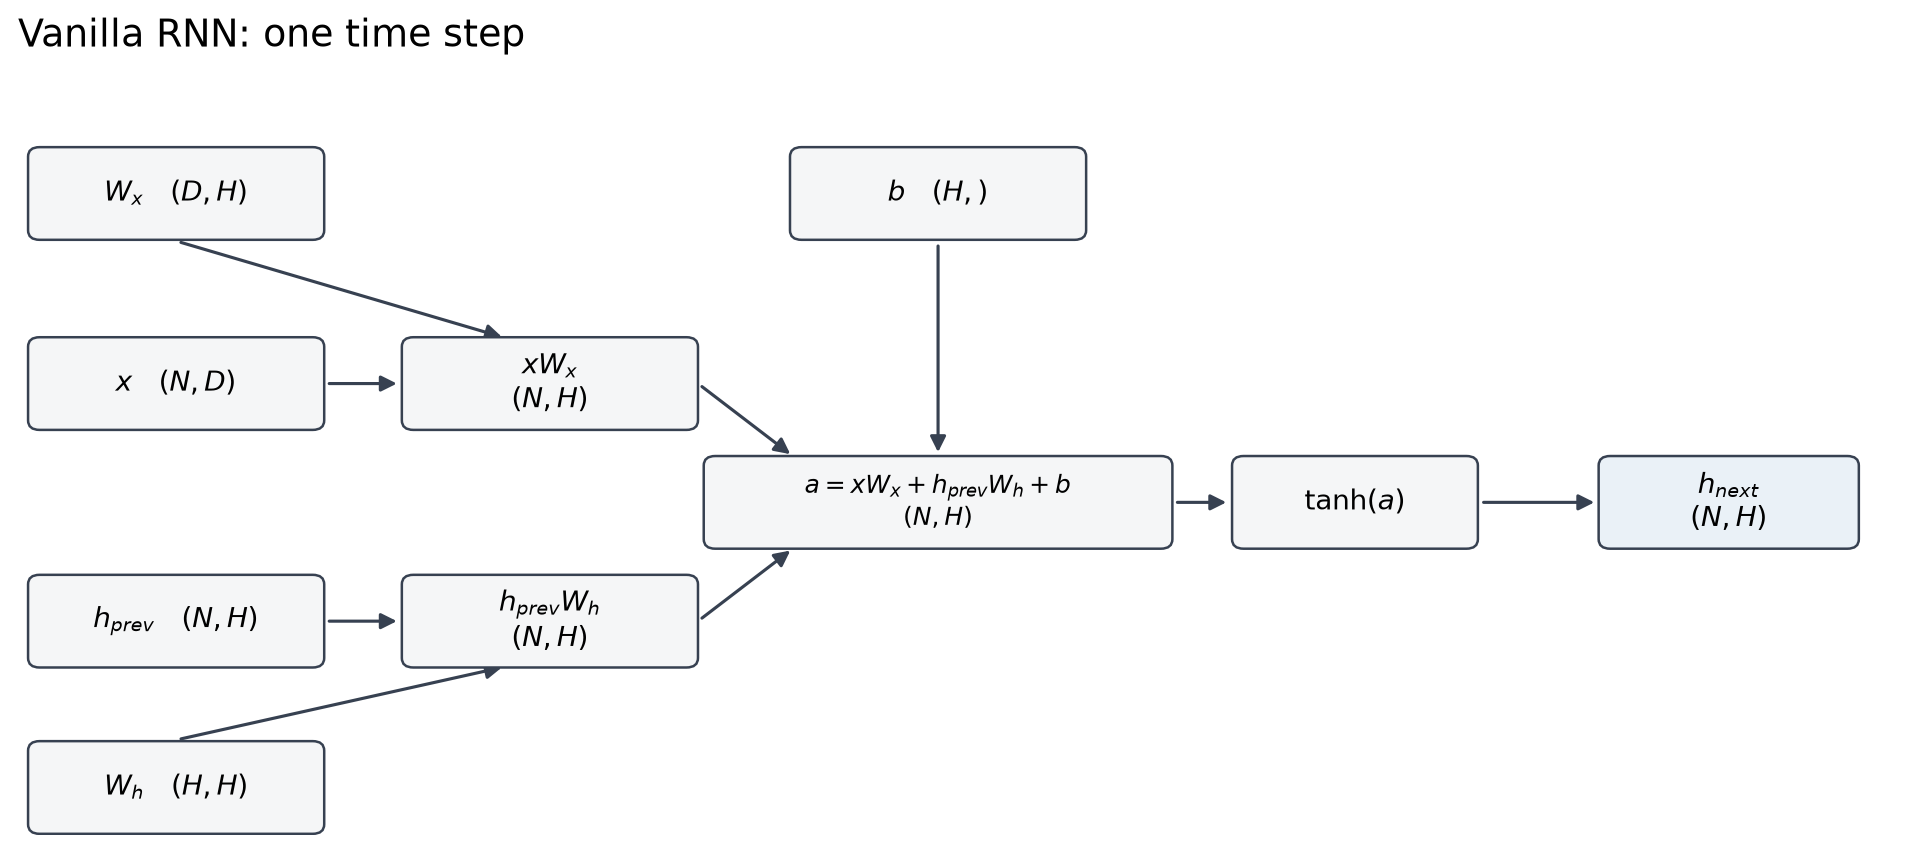

For a batch of $N$ samples, $x\in\mathbb{R}^{N\times D}$ and
$h_{prev}\in\mathbb{R}^{N\times H}$. The weights are
$W_x\in\mathbb{R}^{D\times H}$, $W_h\in\mathbb{R}^{H\times H}$ and
$b\in\mathbb{R}^{H}$. The forward pass is

$$a=xW_x+h_{prev}W_h+b,\qquad h_{next}=\tanh(a).\tag{4.1}$$

Both products, $a$, and $h_{next}$ have shape $(N,H)$; the bias broadcasts over
the batch. The cache stores $x,h_{prev},W_x,W_h,a$.

Given $dh_{next}=dnext\_h\in\mathbb{R}^{N\times H}$, differentiate tanh first:

$$da=dh_{next}\odot[1-\tanh^2(a)].\tag{4.2}$$

Each term in (4.1) receives $da$. The input and previous-state gradients are

$$dx=daW_x^T\in\mathbb{R}^{N\times D},\qquad
dh_{prev}=daW_h^T\in\mathbb{R}^{N\times H}.\tag{4.3}$$

For the weights, sum the sample contributions using

$$dW_x=x^Tda\in\mathbb{R}^{D\times H},\qquad
dW_h=h_{prev}^Tda\in\mathbb{R}^{H\times H}.\tag{4.4}$$

Sum over the batch for the shared bias:

$$db=\sum_{n=1}^N da_n\in\mathbb{R}^{H}.\tag{4.5}$$


In [10]:
N, D, H = 4, 5, 6
x = np.random.randn(N, D)
h = np.random.randn(N, H)
Wx = np.random.randn(D, H)
Wh = np.random.randn(H, H)
b = np.random.randn(H)

out, cache = rnn_step_forward(x, h, Wx, Wh, b)

dnext_h = np.random.randn(*out.shape)

fx = lambda x: rnn_step_forward(x, h, Wx, Wh, b)[0]
fh = lambda prev_h: rnn_step_forward(x, h, Wx, Wh, b)[0]
fWx = lambda Wx: rnn_step_forward(x, h, Wx, Wh, b)[0]
fWh = lambda Wh: rnn_step_forward(x, h, Wx, Wh, b)[0]
fb = lambda b: rnn_step_forward(x, h, Wx, Wh, b)[0]

dx_num = eval_numerical_gradient_array(fx, x, dnext_h)
dprev_h_num = eval_numerical_gradient_array(fh, h, dnext_h)
dWx_num = eval_numerical_gradient_array(fWx, Wx, dnext_h)
dWh_num = eval_numerical_gradient_array(fWh, Wh, dnext_h)
db_num = eval_numerical_gradient_array(fb, b, dnext_h)

dx, dprev_h, dWx, dWh, db = rnn_step_backward(dnext_h, cache)

print("dx error: ", rel_error(dx_num, dx))
print("dprev_h error: ", rel_error(dprev_h_num, dprev_h))
print("dWx error: ", rel_error(dWx_num, dWx))
print("dWh error: ", rel_error(dWh_num, dWh))
print("db error: ", rel_error(db_num, db))

dx error:  4.66374696231372e-10
dprev_h error:  4.015668743841703e-10
dWx error:  4.231516104263316e-10
dWh error:  2.540396805034803e-10
db error:  2.7828446496827918e-11


## Vanilla RNN: forward (2 points)
Now that you have implemented the forward and backward passes for a single timestep of a vanilla RNN, you will combine these pieces to implement a RNN that process an entire sequence of data.

In the file `ECSE552/rnn_layers.py`, implement the function `rnn_forward`. This should be implemented using the `rnn_step_forward` function that you defined above. After doing so run the following to check your implementation. You should see errors less than `1e-7`.

In [11]:
N, T, D, H = 2, 3, 4, 5

x = np.linspace(-0.1, 0.3, num=N * T * D).reshape(N, T, D)
h0 = np.linspace(-0.3, 0.1, num=N * H).reshape(N, H)
Wx = np.linspace(-0.2, 0.4, num=D * H).reshape(D, H)
Wh = np.linspace(-0.4, 0.1, num=H * H).reshape(H, H)
b = np.linspace(-0.7, 0.1, num=H)

h, _ = rnn_forward(x, h0, Wx, Wh, b)
expected_h = np.asarray(
    [
        [
            [-0.42070749, -0.27279261, -0.11074945, 0.05740409, 0.22236251],
            [-0.39525808, -0.22554661, -0.0409454, 0.14649412, 0.32397316],
            [-0.42305111, -0.24223728, -0.04287027, 0.15997045, 0.35014525],
        ],
        [
            [-0.55857474, -0.39065825, -0.19198182, 0.02378408, 0.23735671],
            [-0.27150199, -0.07088804, 0.13562939, 0.33099728, 0.50158768],
            [-0.51014825, -0.30524429, -0.06755202, 0.17806392, 0.40333043],
        ],
    ]
)
print("h error: ", rel_error(expected_h, h))

h error:  7.728466151011529e-08


## Vanilla RNN: backward (3 points)
In the file `cs231n/rnn_layers.py`, implement the backward pass for a vanilla RNN in the function `rnn_backward`. This should run back-propagation over the entire sequence, calling into the `rnn_step_backward` function that you defined above.


For this function you need to show add the explaination with equations of how you calculated the gradient for the layer.


### Vanilla RNN: sequence and backpropagation through time

The input sequence has shape $(N,T,D)$ and $h_0$ has shape $(N,H)$.
We use mathematical time indices $t=1,\ldots,T$; `x[:, t-1, :]` is $x_t$ in code.
The same weights from (4.1) are reused at every time step:

$$a_t=x_tW_x+h_{t-1}W_h+b,\qquad h_t=\tanh(a_t).\tag{5.1}$$

The forward loop saves each $(N,H)$ hidden state in the output
$h\in\mathbb{R}^{N\times T\times H}$ and stores a cache for each step.

Let $G_t=dh[:,t-1,:]$ be the direct upstream gradient for $h_t$ from the
sequence output. There is also a gradient arriving through the recurrent path
from the next step. Call that gradient $r_t$, and initialize $r_T=0$.
Walking backward from $T$ to 1, we combine both paths before differentiating:

$$\bar{h}_t=G_t+r_t,\qquad
da_t=\bar{h}_t\odot(1-h_t^2).\tag{5.2}$$

All three arrays in (5.2) have shape $(N,H)$. The step backward pass then gives

$$dx_t=da_tW_x^T,\qquad r_{t-1}=da_tW_h^T.\tag{5.3}$$

We store $dx_t:(N,D)$ in the corresponding slice of $dx:(N,T,D)$.
Since the weights and bias are shared, we add their gradients over time:

$$dW_x=\sum_{t=1}^T x_t^Tda_t,\qquad
dW_h=\sum_{t=1}^T h_{t-1}^Tda_t,\qquad
db=\sum_{t=1}^T\sum_n da_{t,n}.\tag{5.4}$$

Their shapes remain $(D,H)$, $(H,H)$ and $(H,)$ respectively. After the last
backward iteration, the remaining recurrent gradient is

$$dh_0=r_0\in\mathbb{R}^{N\times H}.\tag{5.5}$$

`dprev_h` carries the recurrent gradient from one backward step to the next.

In [12]:
N, D, T, H = 2, 3, 10, 5

x = np.random.randn(N, T, D)
h0 = np.random.randn(N, H)
Wx = np.random.randn(D, H)
Wh = np.random.randn(H, H)
b = np.random.randn(H)

out, cache = rnn_forward(x, h0, Wx, Wh, b)

dout = np.random.randn(*out.shape)

dx, dh0, dWx, dWh, db = rnn_backward(dout, cache)

fx = lambda x: rnn_forward(x, h0, Wx, Wh, b)[0]
fh0 = lambda h0: rnn_forward(x, h0, Wx, Wh, b)[0]
fWx = lambda Wx: rnn_forward(x, h0, Wx, Wh, b)[0]
fWh = lambda Wh: rnn_forward(x, h0, Wx, Wh, b)[0]
fb = lambda b: rnn_forward(x, h0, Wx, Wh, b)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
dh0_num = eval_numerical_gradient_array(fh0, h0, dout)
dWx_num = eval_numerical_gradient_array(fWx, Wx, dout)
dWh_num = eval_numerical_gradient_array(fWh, Wh, dout)
db_num = eval_numerical_gradient_array(fb, b, dout)

print("dx error: ", rel_error(dx_num, dx))
print("dh0 error: ", rel_error(dh0_num, dh0))
print("dWx error: ", rel_error(dWx_num, dWx))
print("dWh error: ", rel_error(dWh_num, dWh))
print("db error: ", rel_error(db_num, db))

dx error:  1.3388271219598545e-08
dh0 error:  4.664689654572685e-10
dWx error:  4.087523251753286e-09
dWh error:  2.9257090636121614e-09
db error:  6.703323530103649e-10


# LSTM (10 points)
If you read recent papers, you'll see that many people use a variant on the vanialla RNN called Long-Short Term Memory (LSTM) RNNs. Vanilla RNNs can be tough to train on long sequences due to vanishing and exploding gradiants caused by repeated matrix multiplication. LSTMs solve this problem by replacing the simple update rule of the vanilla RNN with a gating mechanism as follows.

Similar to the vanilla RNN, at each timestep we receive an input $x_t\in\mathbb{R}^D$ and the previous hidden state $h_{t-1}\in\mathbb{R}^H$; the LSTM also maintains an $H$-dimensional *cell state*, so we also receive the previous cell state $c_{t-1}\in\mathbb{R}^H$. The learnable parameters of the LSTM are an *input-to-hidden* matrix $W_x\in\mathbb{R}^{4H\times D}$, a *hidden-to-hidden* matrix $W_h\in\mathbb{R}^{4H\times H}$ and a *bias vector* $b\in\mathbb{R}^{4H}$.

At each timestep we first compute an *activation vector* $a\in\mathbb{R}^{4H}$ as $a=W_xx_t + W_hh_{t-1}+b$. We then divide this into four vectors $a_i,a_f,a_o,a_g\in\mathbb{R}^H$ where $a_i$ consists of the first $H$ elements of $a$, $a_f$ is the next $H$ elements of $a$, etc. We then compute the *input gate* $g\in\mathbb{R}^H$, *forget gate* $f\in\mathbb{R}^H$, *output gate* $o\in\mathbb{R}^H$ and *block input* $g\in\mathbb{R}^H$ as

$$
\begin{align*}
i = \sigma(a_i) \hspace{2pc}
f = \sigma(a_f) \hspace{2pc}
o = \sigma(a_o) \hspace{2pc}
g = \tanh(a_g)
\end{align*}
$$

where $\sigma$ is the sigmoid function and $\tanh$ is the hyperbolic tangent, both applied elementwise.

Finally we compute the next cell state $c_t$ and next hidden state $h_t$ as

$$
c_{t} = f\odot c_{t-1} + i\odot g \hspace{4pc}
h_t = o\odot\tanh(c_t)
$$

where $\odot$ is the elementwise product of vectors.

In the rest of the notebook we will implement the LSTM update rule and apply it to the image captioning task.

## LSTM: step forward (2 points)
Implement the forward pass for a single timestep of an LSTM in the `lstm_step_forward` function in the file `ECSE552/rnn_layers.py`. This should be similar to the `rnn_step_forward` function that you implemented above, but using the LSTM update rule instead.

Once you are done, run the following to perform a simple test of your implementation. You should see errors around `1e-8` or less.

In [13]:
N, D, H = 3, 4, 5
x = np.linspace(-0.4, 1.2, num=N * D).reshape(N, D)
prev_h = np.linspace(-0.3, 0.7, num=N * H).reshape(N, H)
prev_c = np.linspace(-0.4, 0.9, num=N * H).reshape(N, H)
Wx = np.linspace(-2.1, 1.3, num=4 * D * H).reshape(D, 4 * H)
Wh = np.linspace(-0.7, 2.2, num=4 * H * H).reshape(H, 4 * H)
b = np.linspace(0.3, 0.7, num=4 * H)

next_h, next_c, cache = lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)

expected_next_h = np.asarray(
    [
        [0.24635157, 0.28610883, 0.32240467, 0.35525807, 0.38474904],
        [0.49223563, 0.55611431, 0.61507696, 0.66844003, 0.7159181],
        [0.56735664, 0.66310127, 0.74419266, 0.80889665, 0.858299],
    ]
)
expected_next_c = np.asarray(
    [
        [0.32986176, 0.39145139, 0.451556, 0.51014116, 0.56717407],
        [0.66382255, 0.76674007, 0.87195994, 0.97902709, 1.08751345],
        [0.74192008, 0.90592151, 1.07717006, 1.25120233, 1.42395676],
    ]
)

print("next_h error: ", rel_error(expected_next_h, next_h))
print("next_c error: ", rel_error(expected_next_c, next_c))

next_h error:  5.7054131967097955e-09
next_c error:  5.8143123088804145e-09


## LSTM: step backward (3 points)
Implement the backward pass for a single LSTM timestep in the function `lstm_step_backward` in the file `ECSE552/rnn_layers.py`. Once you are done, run the following to perform numeric gradient checking on your implementation. You should see errors around `1e-8` or less.

For this function you need to show the computational graph and explain each step of how you computed the gradient.

### LSTM: one step

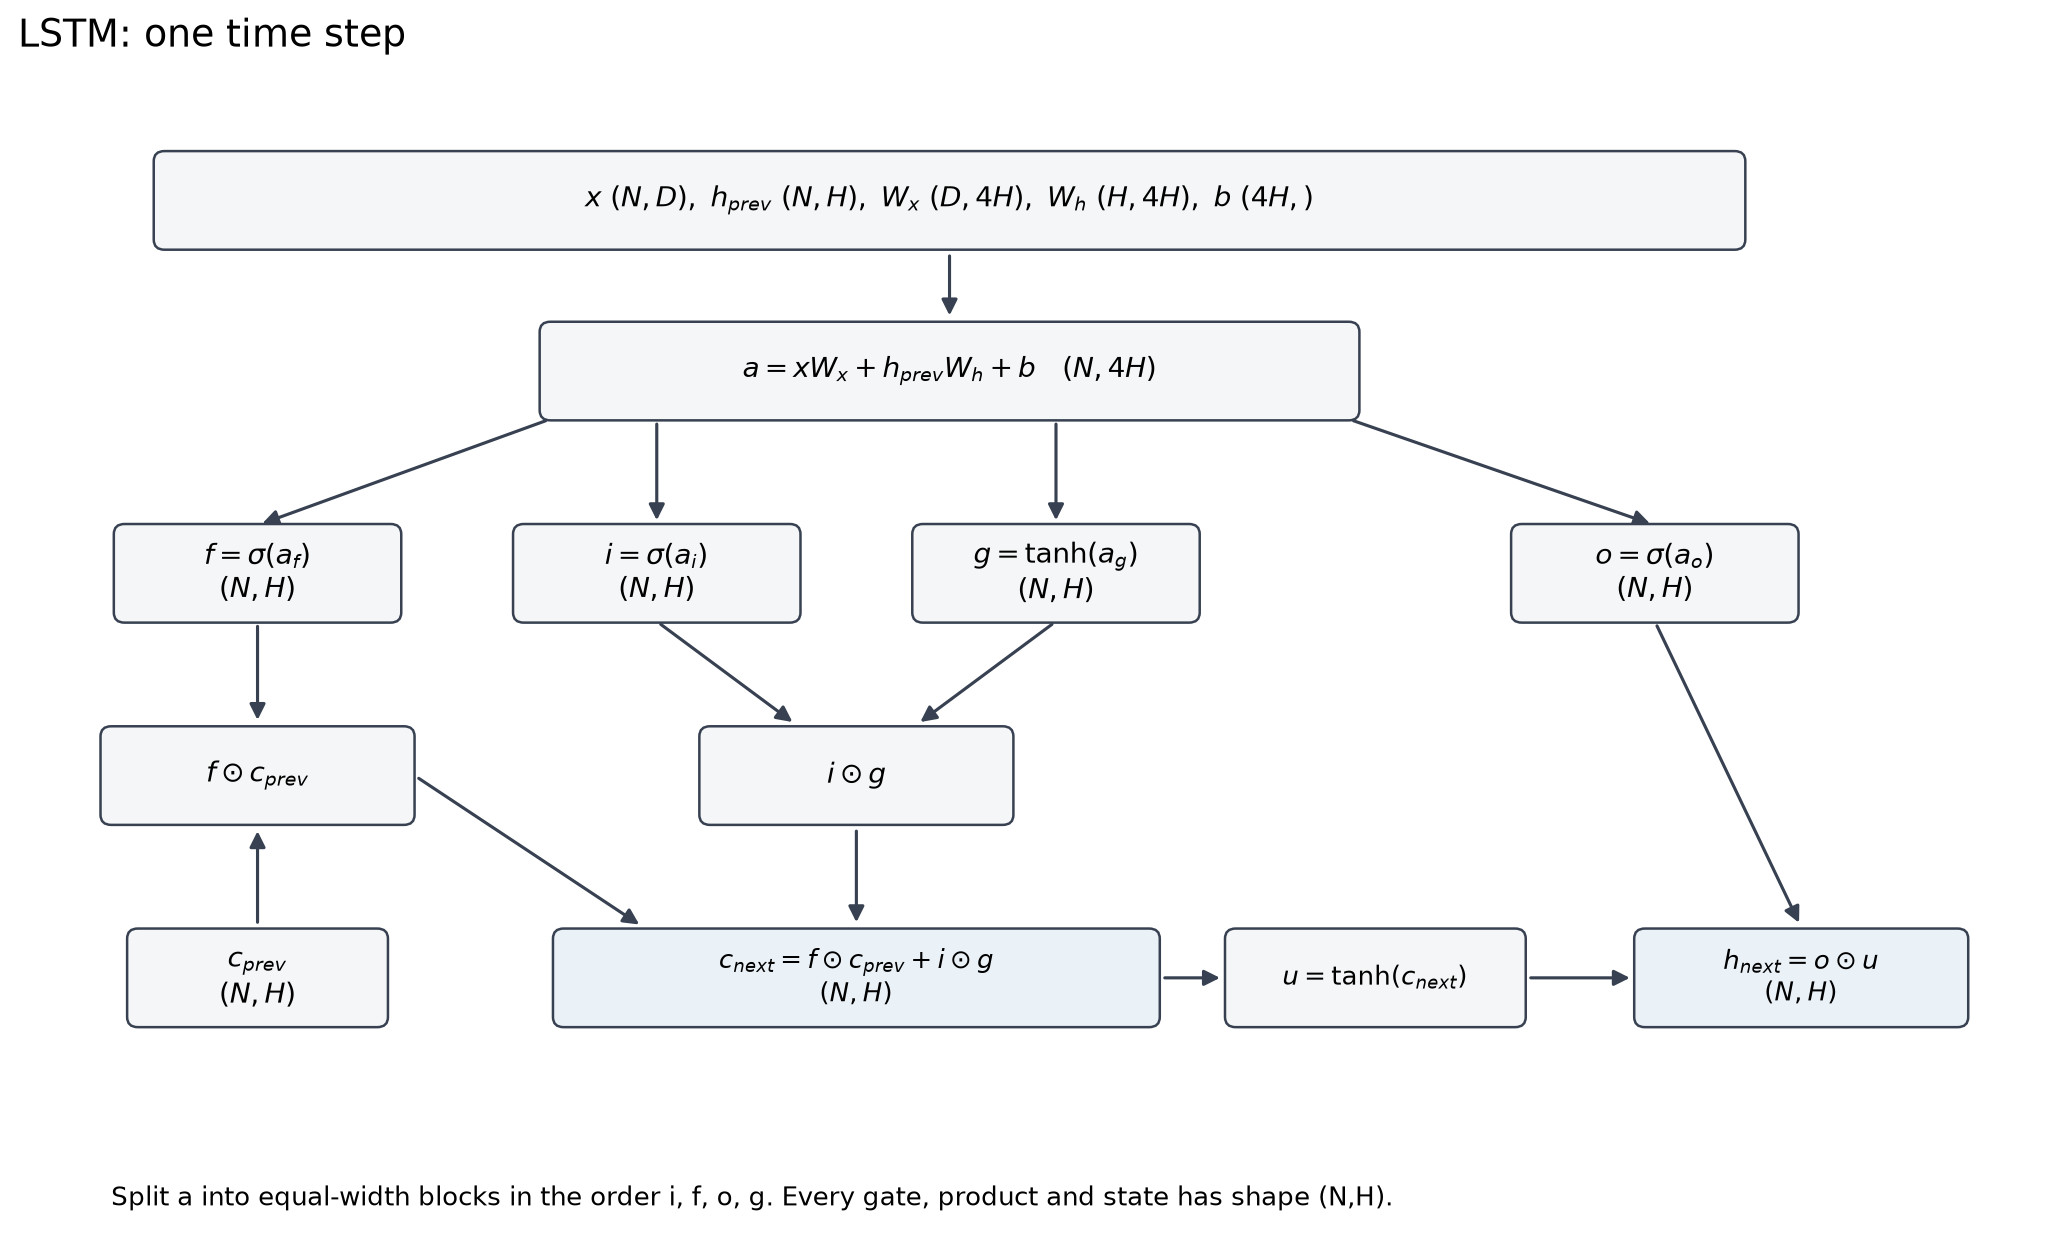

Here $x:(N,D)$, $h_{prev},c_{prev}:(N,H)$,
$W_x:(D,4H)$, $W_h:(H,4H)$ and $b:(4H,)$. The forward affine transformation
produces four blocks of width $H$, in the order used by the code:

$$a=xW_x+h_{prev}W_h+b=[a_i\ a_f\ a_o\ a_g]\in\mathbb{R}^{N\times4H}.
\tag{6.1}$$

$$i=\sigma(a_i),\quad f=\sigma(a_f),\quad o=\sigma(a_o),\quad
g=\tanh(a_g),\qquad \sigma(u)=\frac{1}{1+e^{-u}}.\tag{6.2}$$

Every gate and the candidate $g$ have shape $(N,H)$. The cell and hidden states are

$$c_{next}=f\odot c_{prev}+i\odot g,\qquad
h_{next}=o\odot\tanh(c_{next}).\tag{6.3}$$

The backward function receives $dh_{next}=dnext\_h$ and $dc_{next}=dnext\_c$,
both $(N,H)$. The cell receives one gradient directly and another through
$h_{next}$. With $u=\tanh(c_{next})$, their sum is

$$\bar{c}=dc_{next}+dh_{next}\odot o\odot(1-u^2),\qquad
do=dh_{next}\odot u.\tag{6.4}$$

Differentiate the two products in the cell update:

$$df=\bar{c}\odot c_{prev},\qquad dc_{prev}=\bar{c}\odot f,\qquad
di=\bar{c}\odot g,\qquad dg=\bar{c}\odot i.\tag{6.5}$$

All gradients so far have shape $(N,H)$. Next apply the sigmoid and tanh derivatives:

$$da_i=di\odot i\odot(1-i),\quad
da_f=df\odot f\odot(1-f),\quad
da_o=do\odot o\odot(1-o),\quad
da_g=dg\odot(1-g^2).\tag{6.6}$$

Concatenate in the same order as the forward pass:

$$da=[da_i\ da_f\ da_o\ da_g]\in\mathbb{R}^{N\times4H}.\tag{6.7}$$

The affine backward pass gives

$$dx=daW_x^T\in\mathbb{R}^{N\times D},\qquad
dh_{prev}=daW_h^T\in\mathbb{R}^{N\times H},\tag{6.8}$$

$$dW_x=x^Tda\in\mathbb{R}^{D\times4H},\qquad
dW_h=h_{prev}^Tda\in\mathbb{R}^{H\times4H},\qquad
db=\sum_n da_n\in\mathbb{R}^{4H}.\tag{6.9}$$

The cell gradient in (6.4) includes both the incoming cell gradient and the
hidden-state path. `dprev_c` carries this result through the forget gate.

In [14]:
N, D, H = 4, 5, 6
x = np.random.randn(N, D)
prev_h = np.random.randn(N, H)
prev_c = np.random.randn(N, H)
Wx = np.random.randn(D, 4 * H)
Wh = np.random.randn(H, 4 * H)
b = np.random.randn(4 * H)

next_h, next_c, cache = lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)

dnext_h = np.random.randn(*next_h.shape)
dnext_c = np.random.randn(*next_c.shape)

fx_h = lambda x: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[0]
fh_h = lambda h: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[0]
fc_h = lambda c: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[0]
fWx_h = lambda Wx: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[0]
fWh_h = lambda Wh: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[0]
fb_h = lambda b: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[0]

fx_c = lambda x: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[1]
fh_c = lambda h: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[1]
fc_c = lambda c: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[1]
fWx_c = lambda Wx: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[1]
fWh_c = lambda Wh: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[1]
fb_c = lambda b: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[1]

num_grad = eval_numerical_gradient_array

dx_num = num_grad(fx_h, x, dnext_h) + num_grad(fx_c, x, dnext_c)
dh_num = num_grad(fh_h, prev_h, dnext_h) + num_grad(fh_c, prev_h, dnext_c)
dc_num = num_grad(fc_h, prev_c, dnext_h) + num_grad(fc_c, prev_c, dnext_c)
dWx_num = num_grad(fWx_h, Wx, dnext_h) + num_grad(fWx_c, Wx, dnext_c)
dWh_num = num_grad(fWh_h, Wh, dnext_h) + num_grad(fWh_c, Wh, dnext_c)
db_num = num_grad(fb_h, b, dnext_h) + num_grad(fb_c, b, dnext_c)

dx, dh, dc, dWx, dWh, db = lstm_step_backward(dnext_h, dnext_c, cache)

print("dx error: ", rel_error(dx_num, dx))
print("dh error: ", rel_error(dh_num, dh))
print("dc error: ", rel_error(dc_num, dc))
print("dWx error: ", rel_error(dWx_num, dWx))
print("dWh error: ", rel_error(dWh_num, dWh))
print("db error: ", rel_error(db_num, db))

dx error:  3.355535337990652e-10
dh error:  1.5790317741648279e-10
dc error:  6.096032421702876e-08
dWx error:  7.504834288868138e-10
dWh error:  2.4855546318718784e-09
db error:  2.340984725272868e-10


## LSTM: forward (2 points)
In the function `lstm_forward` in the file `ECSE552/rnn_layers.py`, implement the `lstm_forward` function to run an LSTM forward on an entire timeseries of data.

When you are done run the following to check your implementation. You should see an error around `1e-7`.

In [15]:
N, D, H, T = 2, 5, 4, 3
x = np.linspace(-0.4, 0.6, num=N * T * D).reshape(N, T, D)
h0 = np.linspace(-0.4, 0.8, num=N * H).reshape(N, H)
Wx = np.linspace(-0.2, 0.9, num=4 * D * H).reshape(D, 4 * H)
Wh = np.linspace(-0.3, 0.6, num=4 * H * H).reshape(H, 4 * H)
b = np.linspace(0.2, 0.7, num=4 * H)

h, cache = lstm_forward(x, h0, Wx, Wh, b)

expected_h = np.asarray(
    [
        [
            [0.01764008, 0.01823233, 0.01882671, 0.0194232],
            [0.11287491, 0.12146228, 0.13018446, 0.13902939],
            [0.31358768, 0.33338627, 0.35304453, 0.37250975],
        ],
        [
            [0.45767879, 0.4761092, 0.4936887, 0.51041945],
            [0.6704845, 0.69350089, 0.71486014, 0.7346449],
            [0.81733511, 0.83677871, 0.85403753, 0.86935314],
        ],
    ]
)

print("h error: ", rel_error(expected_h, h))

h error:  8.610537442272635e-08


## LSTM: backward (3 points)
Implement the backward pass for an LSTM over an entire timeseries of data in the function `lstm_backward` in the file `ECSE552/rnn_layers.py`. When you are done run the following to perform numeric gradient checking on your implementation. You should see errors around `1e-8` or less.

For this function you need to show add the explaination with equations of how you calculated the gradient for the layer.

### LSTM: sequence and backpropagation through time

For $x:(N,T,D)$ and $h_0:(N,H)$, initialize the internal cell to
$c_0=0\in\mathbb{R}^{N\times H}$. At each time step,

$$[a_{i,t}\ a_{f,t}\ a_{o,t}\ a_{g,t}]=x_tW_x+h_{t-1}W_h+b,\tag{7.1}$$

$$i_t=\sigma(a_{i,t}),\quad f_t=\sigma(a_{f,t}),\quad
o_t=\sigma(a_{o,t}),\quad g_t=\tanh(a_{g,t}),\tag{7.2}$$

$$c_t=f_t\odot c_{t-1}+i_t\odot g_t,\qquad
h_t=o_t\odot\tanh(c_t).\tag{7.3}$$

Each gate and state is $(N,H)$, and the affine array is $(N,4H)$. The forward
pass returns the hidden states $h:(N,T,H)$ and caches each step's values.
Cell states are kept internally, not returned as sequence outputs.

For backward, let $G_t=dh[:,t-1,:]$. Two gradients can arrive from the next
step: $r^h_t$ through the hidden state and $r^c_t$ through the cell state.
Initialize both to zero at $t=T$. For $t=T,\ldots,1$, call the single-step
backward function with

$$dh^{in}_t=G_t+r^h_t,\qquad dc^{in}_t=r^c_t.\tag{7.4}$$

There is no extra direct cell-output gradient here because the sequence
function returns only hidden states. Equation (6.4) still adds the hidden
state's contribution to the cell gradient inside the step backward call.
If $da_t:(N,4H)$ is the resulting affine gradient, then

$$dx_t=da_tW_x^T,\qquad r^h_{t-1}=da_tW_h^T,\qquad
r^c_{t-1}=\bar{c}_t\odot f_t.\tag{7.5}$$

Their shapes are $(N,D)$, $(N,H)$ and $(N,H)$. The parameter gradients sum
over the shared uses of the weights and bias:

$$dW_x=\sum_t x_t^Tda_t,\qquad
dW_h=\sum_t h_{t-1}^Tda_t,\qquad
db=\sum_t\sum_n da_{t,n}.\tag{7.6}$$

The returned shapes are $dx:(N,T,D)$, $dW_x:(D,4H)$,
$dW_h:(H,4H)$ and $db:(4H,)$. After the reverse loop,

$$dh_0=r^h_0\in\mathbb{R}^{N\times H}.\tag{7.7}$$

`dprev_h` and `dprev_c` carry the gradients to the preceding step. We do not
return a gradient for $c_0$ because it is fixed at zero.

In [16]:
N, D, T, H = 2, 3, 10, 6

x = np.random.randn(N, T, D)
h0 = np.random.randn(N, H)
Wx = np.random.randn(D, 4 * H)
Wh = np.random.randn(H, 4 * H)
b = np.random.randn(4 * H)

out, cache = lstm_forward(x, h0, Wx, Wh, b)

dout = np.random.randn(*out.shape)

dx, dh0, dWx, dWh, db = lstm_backward(dout, cache)

fx = lambda x: lstm_forward(x, h0, Wx, Wh, b)[0]
fh0 = lambda h0: lstm_forward(x, h0, Wx, Wh, b)[0]
fWx = lambda Wx: lstm_forward(x, h0, Wx, Wh, b)[0]
fWh = lambda Wh: lstm_forward(x, h0, Wx, Wh, b)[0]
fb = lambda b: lstm_forward(x, h0, Wx, Wh, b)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
dh0_num = eval_numerical_gradient_array(fh0, h0, dout)
dWx_num = eval_numerical_gradient_array(fWx, Wx, dout)
dWh_num = eval_numerical_gradient_array(fWh, Wh, dout)
db_num = eval_numerical_gradient_array(fb, b, dout)

print("dx error: ", rel_error(dx_num, dx))
print("dh0 error: ", rel_error(dx_num, dx))
print("dWx error: ", rel_error(dx_num, dx))
print("dWh error: ", rel_error(dx_num, dx))
print("db error: ", rel_error(dx_num, dx))

dx error:  6.270287628076786e-10
dh0 error:  6.270287628076786e-10
dWx error:  6.270287628076786e-10
dWh error:  6.270287628076786e-10
db error:  6.270287628076786e-10
